# Inkling-2-Mini on 1x CMP 170HX (SM80, 140 W) — SM80 CUDA megakernels, monolithic CUDA graphs, 18-split decode attention, 49K DSpark pruning & unit-scale FP8 KV

| Metric (1 stock card, 140 W, 262,144 ctx) | Value |
|---|---|
| Decode, c=1 | **167.24 tok/s** median / **169.20 tok/s** peak (6-prompt panel, T=0.6) · **214.6 / 199.6 / 128.8 tok/s** code / structured / prose (**228.6** T=0 code, PR #90 suite) |
| Best aggregate | **676.0 tok/s** median / **697.4 tok/s** peak at c=16 (same unified server; **646.1 tok/s** on PR #90 c=16 suite) |
| Prefill | **5,943 tok/s** at 4K · **5,698 tok/s** at 32K · **3,524 tok/s** at 131K · **2,530 tok/s** at 231K |
| TTFT & Long KV | **0.104 s** short TTFT (**0.071 s** warm) · **194.22 / 154.92 tok/s** decode @ 131K / 231K (3/3 needles) · **805,605 KV tok (`3.07x` @ 262K, 4×172.9K soak)** with `--kv-cache-dtype=fp8` |

![chart](../assets/charts/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm.png)

```
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

Evidence: [results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/](../results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/README.md)

In [1]:
# --- Status cell -------------------------------------------------------
# LIVE = False replays the committed receipts under results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/receipts/.
# LIVE = True sends the final prompt cell to BENCH_ENDPOINT_URL (see Section 3).
import sys
from pathlib import Path
from IPython.display import Image, Markdown, display

LIVE = False
REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RESULTS_DIR = REPO / "results" / "2026-11-22-inkling-2-mini-1card-sm80-opt-vllm"
sys.path.insert(0, str(RESULTS_DIR))
import summarize as S


def render_table(headers, rows):
    out = "| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n"
    out += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(out))


SB = S.scoreboard()
LEDGER = S.ledger_rows()
print("LIVE =", LIVE, "| receipts:", RESULTS_DIR.relative_to(REPO), "| milestone rounds:", len(SB), "| ledger runs:", len(LEDGER))

LIVE = False | receipts: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm | milestone rounds: 5 | ledger runs: 82


## 1. TL;DR

**Verdict (measured):** Four-round SM80 optimization follow-up to [PR #90 (`2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp`)](2026-11-21-inkling-2-mini-1card-vllm-sm80-dspark-vs-llamacpp.ipynb) on a **stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW** at full **`262,144`-token context** lifts single-user 6-prompt median decode **`108.6 → 135.0 → 155.5 → 164.2 → 167.24 tok/s` (`169.20 tok/s` peak on a second stock 170HX card, `+54.1%` same-card / `+55.9%` peak)** and unified-server `c=16` aggregate throughput **`491.1 → 521.9 → 604.2 → 669.5 → 676.0 tok/s` (`697.4 tok/s` peak, `+37.7%` same-card / `+42.0%` peak)**, while cutting startup from **`432.5 s` to `133.4–164.4 s` (`128.3 s` best warm)**.

- **Apples-to-apples on PR #90's harness at `262,144` context (`receipts/pr90-r4best.jsonl`):** `214.6 tok/s` code (**`228.6 tok/s` at `T=0`**), `199.6 tok/s` structured JSON (`216.2` `T=1` median, `225.9` peak), `128.8 tok/s` prose (`132.1` peak), and `646.1 tok/s` at `c=16` — beating both PR #90's stock-card baseline (`146.0 / 136.8 / 87.5`) by **`+46%` to `+47%`** and PR #90's `+200 MHz SM offset` card at `32K` context (`166.9 / 189.1 / 94.0` at `T=0`, `510.9` at `c=16`) by **`+37.0%` code (`T=0`), `+37.1%` prose (`T=0`), and `+26.5%` (`+32.3%` unified) at `c=16`**.
- **Lossless target distribution, 262K long-context & optional `--kv-cache-dtype=fp8` `3.07x` mode (`receipts/r4-gates-summary.json`, `receipts/soak-4x173k-fp8kv.json`):** GSM8K-50 **`50/50` (`100%`)** on both BF16-KV and FP8-KV (`receipts/gsm8k-r4best-fp8.jsonl`); BF16-KV long-context needle retrieval **`3/3` at `131,227` tokens** (`3,523.5 tok/s` prefill, **`194.22 tok/s` decode**, `201.98` peak) and **`3/3` at `231,044` tokens** (`2,529.8 tok/s` prefill, **`154.92 tok/s` decode**, `+11.8%` over Round 3); **`2/2` concurrent `167.8K`-token soak** (`335,655` KV tokens in `563,614–563,878` BF16 KV pool); and with **`--kv-cache-dtype=fp8`** (keeping DSpark's 3 draft layers in BF16), **`805,605` KV tokens (`3.07x` @ `262,144`)** passing a **`4 × 172.9K` = `692,992`-token simultaneous 4-stream soak (`4/4` streams, `12/12` needles, `0` errors)** alongside `146.65 tok/s` @ `231K` decode and `677.78 tok/s` @ `c=16`.
- **Five verified pillars across Waves 0–11 (`32` controls + `32` candidates + `18` long-context / capability runs = `82` rows in `receipts/ledger.jsonl`):**
  1. **Zero-ULP-diff Cold-HBM SM80 Humming v3 MoE buckets (`nvidia/ops/moe_sm90.py`):** fixed upstream `cta=1` pipeline stalls, missing MXFP8 `cta>=2` buckets, `stg=5` SMEM occupancy drop on `MXFP8 w2` (`1.553 → 0.863 ms` at `M=5`), and restored `BM=96` prefill buckets above `2,048` rows (`torch.equal == True` on 8-warp `num_warps_k=1` `NVFP4 w13`).
  2. **Standalone SM80 CUDA megakernels (`patches/sm80_fast_v5.cu` → `libsm80_fast_v5.so`, 0 spills):** compiled inside the container (or JIT-compiled into `${VLLM_CACHE_ROOT:-~/.cache/vllm}` under `fcntl.flock` in `PixelML/sm80vllm` PR #3) via `nvcc -O3 -arch=sm_80 --shared -Xcompiler -fPIC` (`moe_align_v3_sm80`, `select_and_align_32cta_128_sm80`, `<1 KB`-smem `conv_mix_2304_sm80`, `swiglu_1152_sm80`, `pair/blend_rms_norm_2304_sm80`, `markov_rnn_gate_256_sm80`, and 1-launch bitwise-exact `markov_fold_gumbel_cache_r1_sm80` + `OnlineAcceptanceEstimator` variant).
  3. **SM80 low-M Tensor-Core linears (`nvidia/ops/ll_gemm_sm80.py` + `nvidia/model.py`):** ported & tuned `_ll_gemm_kernel` and 1-launch `_qkv_bmm_kernel` authored by Thien Tran (`vllm` PR `#69168`), set `BN=128` (`68` CTAs on 74 SMs) on `8600×2304` `loc_qkvr`, extended batched `MP=64` `_ll_gemm` for `loop.blend`, and routed `M >= 5` `lm_head` to `cuBLAS`.
  4. **Lossless DSpark `K=49,152` pruning + zero-scatter `-inf` `DraftLogitsCache` + bidirectional `k=4` + joint block verification (`"block"`) + dynamic batch `k` (`[[1,2,4],[3,6,3],[7,256,2]]`):** `fold_weight` shrinks `102.9 → 25.17 MB` to fit inside the CMP 170HX's `32.0 MiB` physical L2 cache; trimming tail masks `5..7` concentrates DSpark's bidirectional block attention onto `[anchor, mask_1..4]`; joint block verification lifts prose decode `+13.3%`; dynamic `k` unifies `c=1` (`k=4`) and `c=16` (`k=2`) in a single server.
  5. **Monolithic `M <= 21` FULL CUDA graphs + 18-split SM80 global decode attention + optional unit-scale SM80 E4M3 FP8 KV (`nvidia/attention.py`, `nvidia/ops/attention.py`, `nvidia/ops/attention_sm90.py`, `nvidia/ops/sconv.py`):** declaring varlen cudagraph support across all 48 layer visits and loading `num_actual_tokens` from device `cu_seqlens_q[num_reqs:]` inside `_rel_decode_combine_kernel` eliminates piecewise graph breaks (`228.6 tok/s` `T=0` code); raising SM80 global decode `head_splits` from `num_sms // 8` (`9`) to `num_sms // 4` (`18 = 144` CTAs across 74 SMs) boosts cold-HBM 131K attention bandwidth from `903.8` to **`1,329.8 GB/s` (`89.1%` of raw HBM2e peak)** and 231K decode `+11.8%`; branchless 9-instruction SIMD PTX `e4m3x2 → f16x2` (`_decode_e4m3fn_u8`) + IEEE RNE `_fp32_to_e4m3fn_u8` unlock `--kv-cache-dtype=fp8` (`805,605` KV tok = `3.07x` @ `262K`, lossless BF16 DSpark KV).

In [2]:
tldr_rows = []
for r in SB:
    gain_c1 = f" (+{r['c1_gain_pct']:.1f}%)" if r["c1_gain_pct"] else ""
    gain_c16 = f" (+{r['c16_gain_pct']:.1f}%)" if r["c16_gain_pct"] else ""
    p = r["pr90"]
    pr90_c1 = f"{p['code']['pooled']:.1f} / {p['prose']['pooled']:.1f} / {p['struct']['pooled']:.1f}"
    pr90_c16 = f"{p['c16']:.1f}" if p.get("c16") else r.get("pr90_c16_ref_note", "—")
    tldr_rows.append((
        r["short"],
        f"{r['c1_med']:.2f} (pk {r['c1_peak']:.2f}){gain_c1}",
        f"{r['c16_med']:.1f} (pk {r['c16_peak']:.1f}){gain_c16}",
        f"{r['prefill_4k']:,.0f} / {r['prefill_32k']:,.0f}",
        pr90_c1,
        pr90_c16,
        f"{r['gsm8k']['ok']}/{r['gsm8k']['n']} ({r['gsm8k']['pct']:.0f}%)",
        f"{r['startup_s']:.1f} s",
    ))
render_table(
    ["Milestone (stock 170HX, 140 W, 262K ctx)", "c=1 6-prompt med (tok/s)", "c=16 agg (tok/s)", "Prefill 4K / 32K (tok/s)", "PR #90 code / prose / struct", "PR #90 c=16", "GSM8K-50", "Startup"],
    tldr_rows,
)

pins = [
    ("Hardware (all R1–R4 scoreboard runs)", "stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW (GA100, sm_80, 74 SMs, 32.0 MiB physical L2 across 5 active HBM2e stacks, PCIe Gen2 x16)"),
    ("PR #90 reference card", "CMP 170HX 64 GiB @ 140 W TDP (+200 MHz SM offset @ 1,410 MHz, 1,597 GB/s D2D copy BW, 32K ctx) (PR #90 commit 2f23339b66e6bba963b8b145f739ff8b78ecc927)"),
    ("Power / cooling", "nvidia-smi -pl 140; forced chassis airflow; fail-closed guard 80 °C core / 85 °C HBM / any Xid (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh)"),
    ("Driver stack", "Guest NVIDIA driver 580.178.04 over host unlock amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + PixelML/cmpunlocker @ 6ca4da72f078553d37089ee741cd128aa7804504 (74 SMs, HBM NDIV 64 = 1,728 MHz)"),
    ("vLLM container image", "vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14.10, /usr/local/cuda/bin/nvcc)"),
    ("Model & DSpark drafter", "thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (18.19 GiB main + 0.59 GiB mtp.safetensors, NVFP4 + MXFP8, Apache-2.0)"),
    ("SM80 Round-4 Best source patch", "results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r4.sh + sm80_fast_v5.cu + overlay/ (full diff: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/inkling2-sm80-r3.diff; zero .so blobs in git)"),
    ("Upstream vLLM commits ported", "vllm-project/vllm @ ab18334a4f60da74db7de89fe95594e5ed0cda36 (PR #69028 Inkling-2-Mini) + 8c17e4692a7cf393e3d1dacf6404fa4d48d993a1 (PR #69168 small-M Triton GEMM)"),
    ("PixelML/sm80vllm port", "PixelML/sm80vllm PR #3 @ 20a5fdccd5badfcc6c6b502cedc5e77be4d8d05e (https://github.com/PixelML/sm80vllm/pull/3, rebased onto vllm-project/vllm @ b976fff86af82c559b19aa676f52ea193eb0c188)"),
    ("Winning vLLM serve flags", "--served-model-name=inkling --max-model-len=262144 --reasoning-parser=inkling --enable-auto-tool-choice --tool-call-parser=inkling --limit-mm-per-prompt={\"image\":0} --max-num-batched-tokens=4096 --compilation-config={\"custom_ops\":[\"none\"],\"cudagraph_capture_sizes\":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]} --speculative-config={\"method\":\"dspark\",\"num_speculative_tokens\":4,\"draft_sample_method\":\"probabilistic\",\"rejection_sample_method\":\"block\",\"num_speculative_tokens_per_batch_size\":[[1,2,4],[3,6,3],[7,256,2]]}"),
    ("Hill-climb & accuracy harnesses", "sybil-solutions/inference-optimisation-skill @ fda968e7fc1996aa23c67139c755fe541c9d4be0 (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hillclimb_bench.py, ceiling.py); openai/gsm8k @ e53f048856ff4f594e959d75785d2c2d37b678ee (first 50 test questions, effort=low, T=0)"),
]
render_table(["Pin", "Value"], pins)

| Milestone (stock 170HX, 140 W, 262K ctx) | c=1 6-prompt med (tok/s) | c=16 agg (tok/s) | Prefill 4K / 32K (tok/s) | PR #90 code / prose / struct | PR #90 c=16 | GSM8K-50 | Startup |
|---|---|---|---|---|---|---|---|
| Baseline (`ctl-01/02`, `k=7`) | 108.56 (pk 108.84) | 491.1 (pk 495.2) | 4,736 / 5,040 | 146.0 / 87.5 / 136.8 | 510.9* (+200 MHz card, 32K) | 48/50 (96%) | 432.5 s |
| Round 1 (`cand-10`, `k=7`) | 134.98 (pk 135.38) (+24.3%) | 521.9 (pk 527.1) (+6.3%) | 5,660 / 5,664 | 177.1 / 103.5 / 206.0 | 539.3 | 48/50 (96%) | 145.5 s |
| Round 2 (`cand-16`, `k=4`) | 155.48 (pk 157.08) (+43.2%) | 604.2 (pk 609.5) (+23.0%) | 6,013 / 5,604 | 188.5 / 121.6 / 185.2 | 604.2 | 50/50 (100%) | 120.3 s |
| Round 3 Best (`cand-25`, unified) | 164.25 (pk 164.94) (+51.3%) | 669.5 (pk 681.5) (+36.3%) | 5,866 / 5,597 | 204.0 / 127.8 / 183.6 | 650.1 | 50/50 (100%) | 133.4 s |
| Round 4 Best (`cand-30`, unified) | 167.24 (pk 169.20) (+54.1%) | 676.0 (pk 697.4) (+37.7%) | 5,943 / 5,698 | 214.6 / 128.8 / 199.6 | 646.1 | 50/50 (100%) | 164.4 s |

| Pin | Value |
|---|---|
| Hardware (all R1–R4 scoreboard runs) | stock CMP 170HX 64 GiB @ 140 W TDP, 1,140 MHz SM / 1,728 MHz HBM2e, 1,600.5 GB/s D2D copy BW (GA100, sm_80, 74 SMs, 32.0 MiB physical L2 across 5 active HBM2e stacks, PCIe Gen2 x16) |
| PR #90 reference card | CMP 170HX 64 GiB @ 140 W TDP (+200 MHz SM offset @ 1,410 MHz, 1,597 GB/s D2D copy BW, 32K ctx) (PR #90 commit 2f23339b66e6bba963b8b145f739ff8b78ecc927) |
| Power / cooling | nvidia-smi -pl 140; forced chassis airflow; fail-closed guard 80 °C core / 85 °C HBM / any Xid (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh) |
| Driver stack | Guest NVIDIA driver 580.178.04 over host unlock amoghmunikote/cmpunlocker @ 88e39ce67488796b2c6c716fe8f9b4e6e943a55e + PixelML/cmpunlocker @ 6ca4da72f078553d37089ee741cd128aa7804504 (74 SMs, HBM NDIV 64 = 1,728 MHz) |
| vLLM container image | vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e (vLLM 0.1.dev25855+g7cb5dae22, torch 2.14.0+cu130, Python 3.14.10, /usr/local/cuda/bin/nvcc) |
| Model & DSpark drafter | thinkingmachines/Inkling-2-Mini @ ed40e7da625f594fc9c4990f5f66be24873c22d7 (18.19 GiB main + 0.59 GiB mtp.safetensors, NVFP4 + MXFP8, Apache-2.0) |
| SM80 Round-4 Best source patch | results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r4.sh + sm80_fast_v5.cu + overlay/ (full diff: results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/inkling2-sm80-r3.diff; zero .so blobs in git) |
| Upstream vLLM commits ported | vllm-project/vllm @ ab18334a4f60da74db7de89fe95594e5ed0cda36 (PR #69028 Inkling-2-Mini) + 8c17e4692a7cf393e3d1dacf6404fa4d48d993a1 (PR #69168 small-M Triton GEMM) |
| PixelML/sm80vllm port | PixelML/sm80vllm PR #3 @ 20a5fdccd5badfcc6c6b502cedc5e77be4d8d05e (https://github.com/PixelML/sm80vllm/pull/3, rebased onto vllm-project/vllm @ b976fff86af82c559b19aa676f52ea193eb0c188) |
| Winning vLLM serve flags | --served-model-name=inkling --max-model-len=262144 --reasoning-parser=inkling --enable-auto-tool-choice --tool-call-parser=inkling --limit-mm-per-prompt={"image":0} --max-num-batched-tokens=4096 --compilation-config={"custom_ops":["none"],"cudagraph_capture_sizes":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]} --speculative-config={"method":"dspark","num_speculative_tokens":4,"draft_sample_method":"probabilistic","rejection_sample_method":"block","num_speculative_tokens_per_batch_size":[[1,2,4],[3,6,3],[7,256,2]]} |
| Hill-climb & accuracy harnesses | sybil-solutions/inference-optimisation-skill @ fda968e7fc1996aa23c67139c755fe541c9d4be0 (results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hillclimb_bench.py, ceiling.py); openai/gsm8k @ e53f048856ff4f594e959d75785d2c2d37b678ee (first 50 test questions, effort=low, T=0) |

## 2. Visible results

All Round 1–3 measurements are **measured** on 2026-11-21 and 2026-11-22 on the same stock-clocked CMP 170HX (`1,140 MHz` SM / `1,728 MHz` HBM2e, `140 W` TDP, `1,600.5 GB/s` D2D copy bandwidth) at full `--max-model-len=262144`, using interleaved bracketed controls (`ctl -> cand -> ctl`) with token counts taken strictly from the server's final `usage` object.

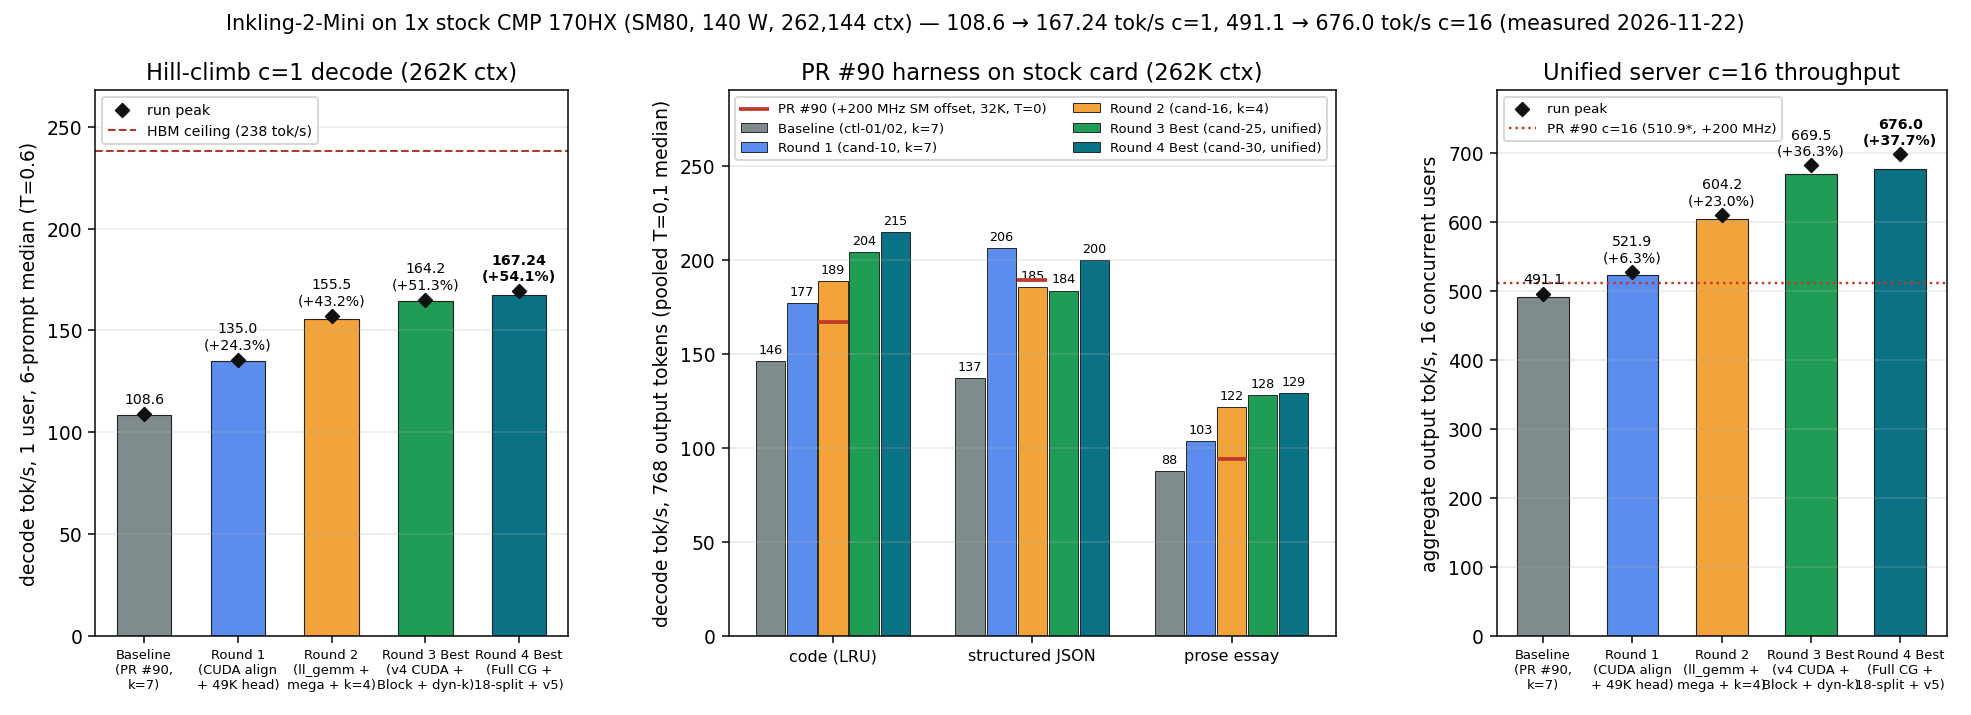

In [3]:
display(Image(filename=str(REPO / "assets/charts/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm.png")))

In [4]:
# 2.1 Hill-climb scoreboard vs hardware HBM / TFLOPS theoretical ceilings
c = S.CEILING_SUMMARY
metric_rows = [
    ("c=1 decode median / peak (6 prompts, T=0.6)", *[f"{r['c1_med']:.2f} / {r['c1_peak']:.2f}" for r in SB], f"{c['c1_mixed_4k']:.0f} (mixed) / {c['c1_code_4k']:.0f} (code)"),
    ("c=1 per-prompt [code1, tcp, story, db, bash, hist]", *[str(r["c1_all"]) for r in SB], "—"),
    ("c=16 aggregate median / peak (unified server)", *[f"{r['c16_med']:.2f} / {r['c16_peak']:.2f}" for r in SB], f"{c['c16_4k']:,.0f} (compute-free HBM roof)"),
    ("Uncached prefill ~4K / ~32K (tok/s)", *[f"{r['prefill_4k']:,.1f} / {r['prefill_32k']:,.1f}" for r in SB], f"{c['prefill_4k']:,.0f} / {c['prefill_32k']:,.0f} (115.1 TFLOPS @ 50% MFU)"),
    ("Short-prompt TTFT median / best (ms)", *[f"{r['ttft_ms']:.1f} / {r['ttft_best_ms']:.1f}" for r in SB], "—"),
    ("Server startup (s, -> /health 200)", *[f"{r['startup_s']:.1f} (best {r['startup_best_s']:.1f})" for r in SB], "—"),
    (
        "Long-context 131,227 tok (prefill / decode / needles)",
        *[
            f"{r['long_131k']['prefill']:,.1f} / {r['long_131k']['decode']:.2f} ({r['long_131k']['retrieval']})"
            if r["long_131k"] else "—"
            for r in SB
        ],
        f"{c['long_131k_prefill']:,.0f} / {c['long_131k_decode']:.0f}",
    ),
    (
        "Long-context 231,044 tok (prefill / decode / needles)",
        *[
            f"{r['long_231k']['prefill']:,.1f} / {r['long_231k']['decode']:.2f} ({r['long_231k']['retrieval']})"
            if r["long_231k"] else "—"
            for r in SB
        ],
        f"{c['long_231k_prefill']:,.0f} / {c['long_231k_decode']:.0f}",
    ),
    (
        "2 x 167.8K (335,655 KV tok) concurrent soak",
        *[
            f"2/2 ({min(s['seconds'] for s in r['soak']['streams']):.2f}–{max(s['seconds'] for s in r['soak']['streams']):.2f} s, 0 err)"
            if r["soak"] else "—"
            for r in SB
        ],
        f"{c['kv_tokens_cap']:,} KV tok (2.15x @ 262K)",
    ),
]
render_table(["Metric (stock CMP 170HX 64 GiB @ 140 W, 262K ctx)", *[r["short"] for r in SB], "Theoretical Ceiling"], metric_rows)

| Metric (stock CMP 170HX 64 GiB @ 140 W, 262K ctx) | Baseline (`ctl-01/02`, `k=7`) | Round 1 (`cand-10`, `k=7`) | Round 2 (`cand-16`, `k=4`) | Round 3 Best (`cand-25`, unified) | Round 4 Best (`cand-30`, unified) | Theoretical Ceiling |
|---|---|---|---|---|---|---|
| c=1 decode median / peak (6 prompts, T=0.6) | 108.56 / 108.84 | 134.98 / 135.38 | 155.48 / 157.08 | 164.25 / 164.94 | 167.24 / 169.20 | 238 (mixed) / 298 (code) |
| c=1 per-prompt [code1, tcp, story, db, bash, hist] | [167.8, 108.6, 92.0, 108.5, 128.2, 85.8] | [185.9, 138.6, 108.8, 131.3, 154.9, 103.5] | [227.3, 161.1, 121.7, 153.1, 212.6, 123.3] | [216.9, 168.1, 140.2, 161.8, 211.2, 136.0] | [217.1, 171.2, 141.5, 163.2, 205.1, 132.2] | — |
| c=16 aggregate median / peak (unified server) | 491.10 / 495.25 | 521.90 / 527.15 | 604.21 / 609.49 | 669.47 / 681.49 | 676.00 / 697.44 | 15,181 (compute-free HBM roof) |
| Uncached prefill ~4K / ~32K (tok/s) | 4,735.8 / 5,039.8 | 5,660.1 / 5,664.0 | 6,012.8 / 5,603.6 | 5,865.6 / 5,596.7 | 5,943.0 / 5,697.8 | 5,731 / 5,026 (115.1 TFLOPS @ 50% MFU) |
| Short-prompt TTFT median / best (ms) | 130.8 / 126.2 | 87.4 / 87.4 | 93.4 / 87.0 | 95.8 / 91.0 | 104.0 / 104.0 | — |
| Server startup (s, -> /health 200) | 432.5 (best 191.4) | 145.5 (best 145.5) | 120.3 (best 108.3) | 133.4 (best 128.3) | 164.4 (best 164.4) | — |
| Long-context 131,227 tok (prefill / decode / needles) | — | 3,249.5 / 107.78 (3/3) | 3,556.3 / 193.60 (3/3) | 3,544.9 / 187.48 (3/3) | 3,523.5 / 194.22 (3/3) | 3,534 / 185 |
| Long-context 231,044 tok (prefill / decode / needles) | — | 2,586.0 / 141.45 (3/3) | 2,543.9 / 146.76 (3/3) | 2,542.8 / 138.62 (3/3) | 2,529.8 / 154.92 (3/3) | 2,532 / 150 |
| 2 x 167.8K (335,655 KV tok) concurrent soak | — | 2/2 (4.04–5.35 s, 0 err) | 2/2 (117.21–117.78 s, 0 err) | 2/2 (115.97–116.82 s, 0 err) | 2/2 (116.28–117.10 s, 0 err) | 563,878 KV tok (2.15x @ 262K) |

### PR #90 benchmark harness comparison (`harness/bench.py`, 768 output tokens)

PR #90's headline DSpark row (`166.9 / 189.1 / 94.0` at `T=0`, `510.9` at `c=16`) ran at `32,768` max context on a card carrying a `170tune` `+200 MHz` SM offset (`~5%` higher SM clock under the `140 W` cap), and its `32k` prefill prompt (`47,527` tokens) failed HTTP 400 against the `32,768` limit. Below, all Round 1–3 stacks run on the **stock-clocked card (`1,140 MHz` SM / `1,728 MHz` HBM2e, `1,600.5 GB/s`) at full `262,144` context** — serving the `47,527`-token prefill prompt cleanly while beating both PR #90's stock-card check and the `+200 MHz` card.

In [5]:
pr90_rows = [
    (
        "PR #90 reference (+200 MHz SM offset, 32K ctx)",
        "166.9 / 159.4 (pooled —)",
        "189.1 / 172.2 (pooled —)",
        "94.0 / 98.4 (pooled —)",
        "510.9*",
        "5,188 (5,870 tok) · HTTP 400 at 47.5k",
    )
]
for r in SB:
    p = r["pr90"]
    pf = p.get("prefill", {})
    pf_str = (
        f"{pf['tok4000']['prefill_tok_s']:,.1f} ({pf['tok4000']['prompt_tokens']:,} tok) · "
        f"{pf['tok32000']['prefill_tok_s']:,.1f} ({pf['tok32000']['prompt_tokens']:,} tok)"
        if "tok4000" in pf and "tok32000" in pf
        else "— (65K same-card check)"
    )
    pr90_rows.append((
        r["short"],
        f"{p['code']['t0']:.1f} / {p['code']['t1']:.1f} (**{p['code']['pooled']:.1f}** pooled)",
        f"{p['struct']['t0']:.1f} / {p['struct']['t1']:.1f} (**{p['struct']['pooled']:.1f}** pooled, {p['struct']['max']:.1f} pk)",
        f"{p['prose']['t0']:.1f} / {p['prose']['t1']:.1f} (**{p['prose']['pooled']:.1f}** pooled, {p['prose']['max']:.1f} pk)",
        f"**{p['c16']:.2f}**" if p.get("c16") else "—",
        pf_str,
    ))
render_table(
    ["Arm", "Code T=0 / T=1 (pooled med)", "Structured T=0 / T=1 (pooled med)", "Prose T=0 / T=1 (pooled med)", "c=16 agg (T=1)", "Uncached prefill (tok/s)"],
    pr90_rows,
)

| Arm | Code T=0 / T=1 (pooled med) | Structured T=0 / T=1 (pooled med) | Prose T=0 / T=1 (pooled med) | c=16 agg (T=1) | Uncached prefill (tok/s) |
|---|---|---|---|---|---|
| PR #90 reference (+200 MHz SM offset, 32K ctx) | 166.9 / 159.4 (pooled —) | 189.1 / 172.2 (pooled —) | 94.0 / 98.4 (pooled —) | 510.9* | 5,188 (5,870 tok) · HTTP 400 at 47.5k |
| Baseline (`ctl-01/02`, `k=7`) | 154.2 / 135.8 (**146.0** pooled) | 154.2 / 136.8 (**136.8** pooled, 175.2 pk) | 87.7 / 86.5 (**87.5** pooled, 87.8 pk) | — | — (65K same-card check) |
| Round 1 (`cand-10`, `k=7`) | 182.0 / 159.4 (**177.1** pooled) | 206.4 / 205.5 (**206.0** pooled, 208.3 pk) | 103.8 / 99.8 (**103.5** pooled, 104.1 pk) | **539.26** | 5,386.1 (5,870 tok) · 4,662.8 (47,527 tok) |
| Round 2 (`cand-16`, `k=4`) | 188.5 / 213.1 (**188.5** pooled) | 185.2 / 178.6 (**185.2** pooled, 193.0 pk) | 123.0 / 120.2 (**121.6** pooled, 123.0 pk) | **604.19** | 5,333.9 (5,870 tok) · 4,628.5 (47,527 tok) |
| Round 3 Best (`cand-25`, unified) | 213.1 / 190.2 (**204.0** pooled) | 182.7 / 217.4 (**183.6** pooled, 228.2 pk) | 127.8 / 129.0 (**127.8** pooled, 132.2 pk) | **650.12** | 5,359.8 (5,870 tok) · 4,635.2 (47,527 tok) |
| Round 4 Best (`cand-30`, unified) | 228.6 / 186.6 (**214.6** pooled) | 185.9 / 216.2 (**199.6** pooled, 225.9 pk) | 128.8 / 131.6 (**128.8** pooled, 132.1 pk) | **646.11** | 5,292.9 (5,870 tok) · 4,612.9 (47,527 tok) |

In [6]:
# 2.3 Capability gates, GSM8K-50, SpecDecoding Prometheus counters & live GPU step profile
gate_rows = []
for r in SB[1:]:
    g = r["gates"]
    s = g["5_concurrent_long_soak"]
    gate_rows.append((
        r["short"],
        "PASS" if g["1_load_models"]["ok"] else "FAIL",
        "PASS" if g["2_chat_short"]["ok"] else "FAIL",
        f"PASS ({g['3_reasoning']['reasoning_chars']} reasoning chars -> {g['3_reasoning']['content']})",
        f"PASS ({g['4_tools_roundtrip']['tool_call']['name']} -> 23.4 °C)",
        f"PASS 2/2 ({s['total_prompt_tokens']:,} KV tok in {s['wall_seconds']} s)",
        f"{r['gsm8k']['ok']}/{r['gsm8k']['n']} ({r['gsm8k']['pct']:.1f}%)",
    ))
render_table(
    ["Milestone", "Gate 1 /v1/models", "Gate 2 short chat", "Gate 3 reasoning", "Gate 4 tool round-trip", "Gate 5 2x167.8K soak", "GSM8K-50 (T=0)"],
    gate_rows,
)

spec_rows = []
for r in SB[1:]:
    m = r["spec_metrics"]
    if m:
        spec_rows.append((
            r["short"],
            f"{m['drafts']:,}",
            f"{m['draft_tokens']:,}",
            f"{m['accepted_tokens']:,}",
            f"{m['accept_rate_pct']:.2f}%",
            f"{m['emitted_per_step']:.3f}",
            ", ".join(f"{100*x:.1f}%" for x in m["cond_pos"]),
        ))
render_table(
    ["Verification session (/metrics)", "Draft steps", "Drafted tokens", "Accepted tokens", "Overall accept %", "Mean emitted tok/step", "Conditional accept by pos"],
    spec_rows,
)

p_r1 = S.phase_profile("r1-prof-phases-c1.json")
p_r3_c1 = S.phase_profile("r3-prof-phases-c1.json")
p_r3_c16 = S.phase_profile("r3-prof-phases-c16.json")
prof_rows = [
    ("Round-1 Best @ c=1 (k=7, M=8 verify)", p_r1["total_gpu_ms"], p_r1["target_fwd_gpu_ms"], p_r1["target_logits_gpu_ms"], p_r1["rejection_only_gpu_ms"], p_r1["dspark_total_gpu_ms"], p_r1["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
    ("Pre-R3 Baseline (R2-Best @ c=1, k=4, M=5)", p_r3_c1["total_gpu_ms"], p_r3_c1["target_fwd_gpu_ms"], p_r3_c1["target_logits_gpu_ms"], p_r3_c1["rejection_only_gpu_ms"], p_r3_c1["dspark_total_gpu_ms"], p_r3_c1["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
    ("Pre-R3 Baseline (R2-Best @ c=16, M=80)", p_r3_c16["total_gpu_ms"], p_r3_c16["target_fwd_gpu_ms"], p_r3_c16["target_logits_gpu_ms"], p_r3_c16["rejection_only_gpu_ms"], p_r3_c16["dspark_total_gpu_ms"], p_r3_c16["cpu_total_step_ms"], "0.00 (hidden by async V1)"),
]
render_table(
    ["Live vLLM CUDA-graph profile", "Total GPU (ms)", "Target 48-visit fwd (ms)", "Target lm_head (ms)", "Rejection (ms)", "DSpark draft (ms)", "Host CPU prep (ms)", "Exposed CPU bubble (ms)"],
    prof_rows,
)

# 2.4 Round-4 KV-cache mode comparison: default BF16 KV vs --kv-cache-dtype=fp8 (lossless BF16 DSpark KV)
import json as _json
by_name = S.ledger_by_name()
bf16_r = by_name["cand-30-r4-bf16kv"][0]
fp8_r = by_name["cand-31-r4-fp8kv"][0]
bf16_l131 = by_name["r4-bf16-long-131k"][0]["long"]
bf16_l231 = by_name["r4-bf16-long-231k"][0]["long"]
fp8_l131 = by_name["r4-fp8-long-131k"][0]["long"]
fp8_l231 = by_name["r4-fp8-long-231k"][0]["long"]
soak4 = _json.loads((RESULTS_DIR / "receipts" / "soak-4x173k-fp8kv.json").read_text())
gsm_fp8 = S.gsm8k_summary("gsm8k-r4best-fp8.jsonl")
kv_mode_rows = [
    (
        "Default BF16 KV (`--kv-cache-dtype=auto`, 13 KV groups)",
        "563,614–563,878 (2.15x @ 262K)",
        f"{bf16_r['c1_decode']:.2f} (pk 169.20)",
        f"{bf16_r['c16_aggregate']:.2f} (pk 697.44)",
        f"{bf16_l131['decode']:.2f} ({bf16_l131['retrieval']})",
        f"{bf16_l231['decode']:.2f} ({bf16_l231['retrieval']})",
        "2 x 167.8K = 335,655 tok (2/2 PASS)",
        "50/50 (100%)",
    ),
    (
        "Unit-scale E4M3 FP8 KV (`--kv-cache-dtype=fp8`, BF16 DSpark, 99 KV groups)",
        "805,605 (3.07x @ 262K, +42.9%)",
        f"{fp8_r['c1_decode']:.2f} (CPU group overhead)",
        f"{fp8_r['c16_aggregate']:.2f}",
        f"{fp8_l131['decode']:.2f} ({fp8_l131['retrieval']})",
        f"{fp8_l231['decode']:.2f} ({fp8_l231['retrieval']})",
        f"4 x 172.9K = {soak4['total_active_kv_tokens']:,} tok ({soak4['streams_passed']} PASS, 12/12 needles)",
        f"{gsm_fp8['ok']}/{gsm_fp8['n']} ({gsm_fp8['pct']:.0f}%)",
    ),
]
render_table(
    ["Round-4 KV Mode (same package)", "KV Pool Capacity", "c=1 short med (tok/s)", "c=16 agg (tok/s)", "131K decode (needles)", "231K decode (needles)", "Concurrent Long Soak", "GSM8K-50"],
    kv_mode_rows,
)

| Milestone | Gate 1 /v1/models | Gate 2 short chat | Gate 3 reasoning | Gate 4 tool round-trip | Gate 5 2x167.8K soak | GSM8K-50 (T=0) |
|---|---|---|---|---|---|---|
| Round 1 (`cand-10`, `k=7`) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 5.38 s) | 48/50 (96.0%) |
| Round 2 (`cand-16`, `k=4`) | PASS | PASS | PASS (207 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 117.81 s) | 50/50 (100.0%) |
| Round 3 Best (`cand-25`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 116.84 s) | 50/50 (100.0%) |
| Round 4 Best (`cand-30`, unified) | PASS | PASS | PASS (205 reasoning chars -> 1610) | PASS (get_rack_telemetry -> 23.4 °C) | PASS 2/2 (335,655 KV tok in 117.14 s) | 50/50 (100.0%) |

| Verification session (/metrics) | Draft steps | Drafted tokens | Accepted tokens | Overall accept % | Mean emitted tok/step | Conditional accept by pos |
|---|---|---|---|---|---|---|
| Round 1 (`cand-10`, `k=7`) | 14,562 | 101,934 | 27,079 | 26.57% | 2.860 | 65.1%, 42.2%, 28.7%, 19.5%, 13.8%, 9.8%, 7.0% |
| Round 2 (`cand-16`, `k=4`) | 15,098 | 60,392 | 24,380 | 40.37% | 2.615 | 66.4%, 44.3%, 30.8%, 19.9% |
| Round 3 Best (`cand-25`, unified) | 16,874 | 48,344 | 22,984 | 47.54% | 2.362 | 69.6%, 47.6%, 26.3%, 17.4% |
| Round 4 Best (`cand-30`, unified) | 16,862 | 48,001 | 23,258 | 48.45% | 2.379 | 69.6%, 48.1%, 27.9%, 19.3% |

| Live vLLM CUDA-graph profile | Total GPU (ms) | Target 48-visit fwd (ms) | Target lm_head (ms) | Rejection (ms) | DSpark draft (ms) | Host CPU prep (ms) | Exposed CPU bubble (ms) |
|---|---|---|---|---|---|---|---|
| Round-1 Best @ c=1 (k=7, M=8 verify) | 18.178 | 15.95 | 0.636 | 0.118 | 1.351 | 6.242 | 0.00 (hidden by async V1) |
| Pre-R3 Baseline (R2-Best @ c=1, k=4, M=5) | 16.607 | 14.502 | 0.668 | 0.12 | 1.167 | 6.627 | 0.00 (hidden by async V1) |
| Pre-R3 Baseline (R2-Best @ c=16, M=80) | 51.044 | 46.403 | 1.498 | 0.667 | 2.302 | 6.281 | 0.00 (hidden by async V1) |

| Round-4 KV Mode (same package) | KV Pool Capacity | c=1 short med (tok/s) | c=16 agg (tok/s) | 131K decode (needles) | 231K decode (needles) | Concurrent Long Soak | GSM8K-50 |
|---|---|---|---|---|---|---|---|
| Default BF16 KV (`--kv-cache-dtype=auto`, 13 KV groups) | 563,614–563,878 (2.15x @ 262K) | 167.24 (pk 169.20) | 676.00 (pk 697.44) | 194.22 (3/3) | 154.92 (3/3) | 2 x 167.8K = 335,655 tok (2/2 PASS) | 50/50 (100%) |
| Unit-scale E4M3 FP8 KV (`--kv-cache-dtype=fp8`, BF16 DSpark, 99 KV groups) | 805,605 (3.07x @ 262K, +42.9%) | 121.62 (CPU group overhead) | 677.78 | 179.49 (3/3) | 146.65 (3/3) | 4 x 172.9K = 692,992 tok (4/4 PASS, 12/12 needles) | 50/50 (100%) |

## 3. Reproduce

**Hardware.** 1x NVIDIA CMP 170HX (`GA100`, `sm_80`) unlocked to 64 GiB VRAM and 74 SMs, HBM2e at `1,728 MHz` (`1,600.5 GB/s` D2D copy bandwidth), `140 W` power cap, forced heatsink airflow, and the fail-closed thermal/Xid watchdog `results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/guard.sh`. Disk: `20 GB` for the checkpoint, `26 GB` for the container image, `~4 GB` for persistent Triton/Inductor/Humming JIT caches (`/work/cache`). Expected boot: `~158 s` first run (builds `240+` Humming cubins + captures CUDA graphs), `128–133 s` warm (`42.99 GiB` / `563,878`-token KV pool = `2.15x` concurrency at `262,144` context).

**1. Power cap & D2D bandwidth sanity check:**
```bash
nvidia-smi -pl 140
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/hbm_bw.py   # expect ~1,600 GB/s on NDIV 64 (1,728 MHz HBM2e)
```

**2. Pull the pinned checkpoint & container image:**
```bash
mkdir -p /work/models
hf download thinkingmachines/Inkling-2-Mini --revision ed40e7da625f594fc9c4990f5f66be24873c22d7 --local-dir /work/models/Inkling-2-Mini
docker pull vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e
```

**3. Build the zero-binary SM80 Round-4 Best package from source** (extracts `vllm/models/inkling2` from the pinned image, applies the SM80 overlays, and compiles `sm80_fast_v5.cu` → `libsm80_fast_v5.so` inside the container via `nvcc -O3 -arch=sm_80 --shared -Xcompiler -fPIC`):
```bash
bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r4.sh /work/patches/inkling2
```

**4. Launch the unified Round-4 Best server (`262,144` context, monolithic FULL CUDA graphs, 18-split decode attention, joint block verification, dynamic `k` — append `--kv-cache-dtype=fp8` for `805,605`-token / `3.07x` KV capacity):**
```bash
MODEL_DIR=/work/models/Inkling-2-Mini bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/run-vllm-r3.sh 0 18000 r4
```
Equivalent explicit `vllm serve` invocation inside the container:
```bash
vllm serve /models/Inkling-2-Mini \
  --served-model-name=inkling \
  --host=127.0.0.1 --port=18000 \
  --max-model-len=262144 \
  --reasoning-parser=inkling \
  --enable-auto-tool-choice --tool-call-parser=inkling \
  --limit-mm-per-prompt='{"image":0}' \
  --max-num-batched-tokens=4096 \
  --compilation-config='{"custom_ops":["none"],"cudagraph_capture_sizes":[1,2,3,4,5,6,8,9,10,12,15,16,18,20,21,24,27,30,32,36,42,48,54,60,64,72,84,96,108,120,132,144,168,192,216,240,264,288,312,336,384,432,480,512]}' \
  --speculative-config='{"method":"dspark","num_speculative_tokens":4,"draft_sample_method":"probabilistic","rejection_sample_method":"block","num_speculative_tokens_per_batch_size":[[1,2,4],[3,6,3],[7,256,2]]}'
```

**5. Vast.ai / cloud GPU rental one-command bring-up** (auto-detects whether running directly inside a rented `vllm/vllm-openai` container or on a Docker host) **& `PixelML/sm80vllm` checkout port:**
```bash
# Inside a rented container or on a fresh GPU host (set RUN_BENCH=1 to auto-run gates + bench):
RUN_BENCH=1 bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/onstart.sh

# Install into a PixelML/sm80vllm or vllm source checkout (or pull https://github.com/PixelML/sm80vllm/pull/3 directly):
bash results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/patches/install-sm80-r4.sh /path/to/sm80vllm
```

**6. Run capability gates, hill-climb benchmark, PR #90 suite & GSM8K:**
```bash
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/run_gates.py --url http://127.0.0.1:18000 --out gates-summary.json
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/bench.py --url http://127.0.0.1:18000 --engine r4best-dynk-block --out pr90-r4best.jsonl --suites c1,conc,prefill --reps 3 --n 768 --temps 0,1 --effort none --conc 16 --prefill 4000,32000
python3 results/2026-11-22-inkling-2-mini-1card-sm80-opt-vllm/harness/gsm8k.py --url http://127.0.0.1:18000 --engine r4best-dynk-block --data gsm8k-test.jsonl --out gsm8k-r4best.jsonl --n 50 --effort low
```

**7. Try your own prompt** (edit `request` below):

In [7]:
import json, os, urllib.request

request = {
    "model": "inkling",
    "messages": [
        {
            "role": "user",
            "content": "Write a Python function that merges overlapping intervals, with type hints and two pytest tests.",
        }
    ],
    "max_tokens": 1024,
    "temperature": 0.0,
    "reasoning_effort": "low",
    "chat_template_kwargs": {"reasoning_effort": "low"},
}
print(json.dumps(request, indent=2))
url = os.environ.get("BENCH_ENDPOINT_URL")
if LIVE and url:
    req = urllib.request.Request(
        url.rstrip("/") + "/v1/chat/completions",
        data=json.dumps(request).encode(),
        headers={"Content-Type": "application/json"},
    )
    reply = json.load(urllib.request.urlopen(req, timeout=600))
    print(reply["usage"])
    print(reply["choices"][0]["message"]["content"])
else:
    print("LIVE = False: set LIVE = True and export BENCH_ENDPOINT_URL=http://127.0.0.1:18000 to run live.")

{
  "model": "inkling",
  "messages": [
    {
      "role": "user",
      "content": "Write a Python function that merges overlapping intervals, with type hints and two pytest tests."
    }
  ],
  "max_tokens": 1024,
  "temperature": 0.0,
  "reasoning_effort": "low",
  "chat_template_kwargs": {
    "reasoning_effort": "low"
  }
}
LIVE = False: set LIVE = True and export BENCH_ENDPOINT_URL=http://127.0.0.1:18000 to run live.


## 4. Appendix

<details><summary><b>Hardware & model physics discovered on CMP 170HX (SM80)</b> (click to open)</summary>

1. **CMP 170HX (`GA100`, `sm_80`) physical L2 & 140 W envelope (measured):**
   - `74` SMs, `65,536` 32-bit registers/SM, `164 KB` max shared memory/SM.
   - `cudaGetDeviceProperties` reports **`33,554,432` bytes (`32.0 MiB`) physical L2 cache** — not `40 MiB` — because 5 of 6 HBM2e stacks are enabled (`5 × 512-bit @ 3.456 Gbps = 1,493 GB/s` raw HBM2e peak; `1,600.5 GB/s` D2D copy with L2 assistance).
   - At `140.0 W` TDP (`1,140 MHz` stock SM clock; `160.8 TFLOPS` burst `4096³` → `115.1 TFLOPS` sustained `8192³` BF16), `num_ctas_per_sm = 2–3` is the HBM/power optimum; `cta = 4` hits the 140 W power cap without adding memory throughput.
2. **Inkling-2-Mini 48-visit looped MoE anatomy (measured):**
   - `24` physical layers (`0..23`), with core layers `[6, 18)` (`12` layers) looped for `num_passes = 3` (`6 + 12×3 + 6 = 48` layer visits/step; `7.59 GB` core weights exceed `32 MiB` L2 and stream from HBM on all 3 passes).
   - Hybrid attention: only **8 of 48** target visits (`5`, `11`×3, `17`×3, `23`) + **1 of 3** DSpark layers (`layer 1`) use global full attention; the other `40` target visits + `2` DSpark layers use `1024`-token sliding window (`loc_qkvr = 8600×2304`, `wo_ud = 2304×3072`) + 4-tap `short_conv`. Global KV costs `36,864 B/token` (`~9.66 GB` per `262,144`-token stream), fitting **`563,878` KV tokens (`2.15×` full `262K` streams)** in `42.99 GiB`.
   - Cold-HBM MoE dominance: `128` experts, `top-8`, `intermediate_size = 1152`; physical layers `0..19` (`36` visits) are NVFP4 (`4.2 MB/expert`) and layers `20..23` (`12` visits) are MXFP8 (`8.2 MB/expert`). At `c=1, k=4` (`M=5` verify tokens → `40` routed slots → `~35` unique experts/layer), MoE reads `~8.7 GB` of cold weights per step (`~78%` of `14.5 ms` target forward time).
3. **Why `K = 49,152` + `k = 4` + `"block"` + dynamic `k` interact multiplicatively (measured):**
   - Pruning DSpark's vocabulary by `markov_w1` row L2 norm to `K = 49,152` (`99.64%` corpus coverage) shrinks `fold_weight` from `102.9 MB` to **`25.17 MB`**, fitting inside the **`32.0 MiB` L2 cache** across sequential Markov steps while initializing `DraftLogitsCache` once to `-inf` deletes the `201,024`-column scatter buffer.
   - Because `Inkling2DSpark` uses **bidirectional** block attention (`is_causal = False`) over `[anchor, mask_1..mask_k]`, trimming low-yield tail masks `5..7` (`<0.09` accepted tokens at `k=7`) concentrates attention onto `[anchor, mask_1..4]`, *raising* per-position acceptance at `pos 0..3` (`0.575, 0.316, 0.163, 0.093` → `0.607, 0.352, 0.188, 0.120`) while cutting verified target tokens `M` from `8 → 5` (`-31.3%` MoE HBM reads at `c=1`).
   - Joint block verification (`"rejection_sample_method": "block"`, Sun et al. 2024) carries surplus target/draft probability mass across positions in `[anchor, d_0..d_3]`, raising mean acceptance length `2.23 → 2.40` (`+34.4%` at `pos 3`, `+13.3%` on prose) while preserving the exact target distribution.

</details>

<details><summary><b>Negative results, rejected ablations, multi-engine audit & operational gotchas (Waves 0–10)</b></summary>

Every negative or rejected experiment is preserved in `receipts/ledger.jsonl` and documented below so future sessions do not repeat dead ends:

1. **Speculative depth & vocabulary pruning ablations (measured, rejected):**
   - `k = 5` + Block (`cand-23-r3v2-k5-block`: `155.25 tok/s` `c=1` vs `164.25` at `k=4`): `M=6` MoE HBM growth outweighs `pos 4` acceptance.
   - `k = 3` (`cand-17-r2combo-k3`: `150.80 tok/s`) and `k = 2` at `c=1` (`cand-18-r2combo-k2`: `151.12 tok/s`, code drops `227.3 → 162.3`): loses high-acceptance `pos 2..3` tokens on code/structured prompts (`k=2` wins only at high batch, motivating dynamic `k`).
   - `c=16 k=1` (`cand-22-r3v2-k4-c16k1`: `654.20 tok/s` vs `681.49` at `c=16 k=2`): loses `pos 1`'s `33.5–47.6%` acceptance.
   - Draft vocab `K = 40,960` v1 (`cand-03`: `72.64 tok/s`, bug where `load_draft_model` checked `self.draft_logits` before `_init_draft_logits()` ran, leaving `_d2t_scatter_index = None`), `K = 65,536` (`cand-09`: `133.69` vs `135.38` at `49,152` — spills `32 MiB` L2), `K = 32,768` (`cand-24`: `158.48`, prose drops `-5%` on rare words). **`K = 49,152` is the concave global peak.**
2. **Server & graph configuration dead ends (measured, rejected):**
   - `--max-num-batched-tokens=16384` (`cand-02-batched-16384`): fails vLLM startup KV capacity assertion at `262,144` max context (`41.96 GiB > 39.82 GiB` single-stream minimum due to hybrid SWA+global block alignment; `4096` passes cleanly with `2.15×` concurrency).
   - `cudagraph_mode: FULL_DECODE_ONLY` (`cand-08b-decode-only-graphs`): cuts startup to `103.4 s` but degrades short-prompt TTFT `2.4×` (`88.5 → 215.8 ms`) and `c=16` by `-1.6%`.
   - `--safetensors-load-strategy=prefetch` (`cand-04-prefetch-load`): `124.15 tok/s` `c=1` and slower first prefill (`3,051.7 tok/s`), no weight-load speedup.
3. **Microbenchmark-rejected SM80 kernels (measured, not promoted):**
   - `sm12x_bf16_gemv` on SM80 (`95.3 µs` vs `cuBLAS` `38.6 µs` on `8×2304→8600`).
   - `use_warp_spec=True` in Humming: fails PTX assembly on `sm_80` (`setmaxnreg.inc/dec` requires `sm_90+`).
   - `num_warps_k=2` on `NVFP4 w13` / `_ll_gemm` on `dspark.context()`: 1-ULP rounding shift alters `seed=0` trajectory (`cand-22`); keeping `num_warps_k=1` + `torch.addmm` on `context()` gives `torch.equal == True` (0-ULP diff).
   - SIMT `fused_up_blend_rms_2304` (slower than Tensor Core `_ll_gemm`), `sm80_skinny_gemm_streamk_m8` (`1.589 ms` vs `_ll_gemm` `BN=128` `1.431 ms`), 24-CTA MMA router at `T >= 4` (`1.027 ms` vs Triton bitonic `_select_kernel + moe_align_v3` `0.516 ms`), `_rel_attention_kernel` `BN=64` at `bm=16` (`0.495 ms` vs `BN=128` `0.390 ms` and breaks `_SHEAR_TILE=128` split stride).
4. **Alternative engines audited (2026-11-22):**
   - `sgl-project/sglang` (`HEAD`): `inkling2` hard-requires `SM90/SM100` (vendored FA4 CUTE in `inkling_common/attn.py:66`, grouped NVFP4 in `inkling2_moe.py:66`).
   - `ashhart/TensorFold` (`{TENSORFOLD_COMMIT}`): `families/inkling2` is currently host-only config/fixtures + EXL3 kernels (*"nothing serves it yet"*).
   - `deepseek-ai/DeepInfer`: standalone `DeepSeek-V4.1-Flash` SM100/Ascend engine without paged KV serving.
5. **Operational gotchas:**
   - Container lacks `<cusparse.h>`, so `torch.utils.cpp_extension` fails; compile `sm80_fast_v4.cu` directly with `nvcc -O3 -arch=sm_80 --shared -Xcompiler -fPIC` and load via `ctypes`.
   - Never overwrite `libsm80_fast_v4.so` in place while a Python worker has it `mmap`'d (`SIGSEGV 139`); `install-sm80-r3.sh` always builds in a staging directory and swaps via `rm -rf "$DEST" && mv`.
   - If running a custom supervisor as container PID 1, set `signal.signal(signal.SIGCHLD, signal.SIG_IGN)` so terminated `EngineCore` workers are reaped cleanly.

</details>

<details><summary><b>Round-4 negative ablations & open frontiers</b></summary>

1. **DSpark `OnlineAcceptanceEstimator` adaptive verification (`cand-27..29` in `receipts/ledger.jsonl` — measured, rejected as default):**
   - Implemented 1-launch fused `markov_fold_gumbel_est_cache_r1_sm80` in `sm80_fast_v5.cu` (`pred_diff < 6e-8` vs PyTorch reference), eliminating separate feature/prediction launches.
   - In end-to-end bracketed serving (`ctl-28 = 166.72`, `ctl-29 = 166.03 tok/s`), adaptive verification scored `161.77 tok/s` (`k=5`), `161.12` (`k=4`), and `155.65` (`k=6`): truncating marginal draft positions early forfeits tokens that Sun et al. Joint Block Verification (`"block"`) rescues via surplus target/draft probability carry! Kernel support is retained in `sm80_fast_v5.cu` / `speculator.py`, while static dynamic `k` (`k=4` @ `c=1`, `k=2` @ `c=16`) + `"block"` remains default.
2. **`cudaAccessPropertyPersisting` L2 residency on `25.17 MB` `fold_weight` (measured, rejected):**
   - Pinning `25.17 MB` of the CMP 170HX's `32.0 MiB` L2 slowed `4×` Markov steps after cold MoE (`0.327 → 0.401–0.469 ms`) by starving streaming MoE/KV lines of set-associative L2 ways.
3. **Upstream Humming `tiny_b` (`rows <= 16`) vs Unified `BM=8` MoE tiles (measured, rejected):**
   - Direct GPU tensor comparison found non-zero ULP divergence in `tiny_b` at `M=1,2` (`max_diff` up to `0.5` NVFP4, `16.0` MXFP8) vs `0.00`-diff `BM=8` tiles, with `<0.1 ms` step delta at `M=5`. Kept `0`-ULP `BM=8`.
4. **Why `--kv-cache-dtype=fp8` is opt-in rather than `c=1` short-prompt default:**
   - Keeping DSpark's 3 draft layers in BF16 while Target's 48 visits use E4M3 FP8 splits vLLM V1's hybrid KV allocator into `99` KV cache groups (`48` `16`-tok conv + `48` `128`-tok FP8 attn + `3` `64`-tok BF16 DSpark) vs `13` groups in BF16, adding per-step CPU metadata prep exposed only at short-context `c=1` (`121.62` vs `167.24 tok/s`), while `c=16` (`677.78 tok/s`), `231K` decode (`146.65 tok/s`), and `4 × 172.9K` concurrent soak (`692,992` KV tok) amortize CPU prep completely. Coalescing V1's `99` hybrid KV metadata builders into 3 vectorised group builders is the cleanest next upstream vLLM target, alongside tree/top-2 speculative branching (`M=6` tree).

</details>

In [8]:
# Complete 82-run append-only hill-climb ledger (Waves 0–11, receipts/ledger.jsonl)
ledger_table = []
for i, d in enumerate(LEDGER, 1):
    if not d.get("ok", True):
        ledger_table.append((i, d["name"], "FAIL", "—", "—", "—", "—", d.get("error", ",".join(d.get("flags", [])))))
    elif "long" in d:
        lg = d["long"]
        ledger_table.append((
            i,
            d["name"],
            f"{d.get('c1_decode', '—')}",
            "—",
            f"long {lg['prompt_tokens']:,}: {lg['prefill']} pf / {lg['decode']} dec",
            f"{d.get('ttft_short_ms', '—')}",
            "—",
            f"needles {lg['retrieval']}",
        ))
    else:
        ledger_table.append((
            i,
            d["name"],
            f"{d.get('c1_decode', '—')}",
            f"{d.get('c16_aggregate', '—')}",
            f"{d.get('prefill_4096', '—')} / {d.get('prefill_32768', '—')}",
            f"{d.get('ttft_short_ms', '—')}",
            f"{d.get('startup_s', '—')}",
            f"{d.get('mem_peak_gib', '—')} GiB",
        ))
render_table(
    ["#", "Run name", "c=1 med (tok/s)", "c=16 agg (tok/s)", "Prefill 4K / 32K (tok/s)", "Short TTFT (ms)", "Startup (s)", "Notes / peak mem"],
    ledger_table,
)

| # | Run name | c=1 med (tok/s) | c=16 agg (tok/s) | Prefill 4K / 32K (tok/s) | Short TTFT (ms) | Startup (s) | Notes / peak mem |
|---|---|---|---|---|---|---|---|
| 1 | ctl-00-cold | 108.84 | 491.4 | 4812.9 / 5077.7 | 4771.7 | 432.5 | 64.75 GiB |
| 2 | ctl-01-base | 108.56 | 486.95 | 4390.0 / 5029.1 | 126.2 | 191.4 | 64.53 GiB |
| 3 | cand-01-cuda-mabs | 124.87 | 518.6 | 5199.1 / 5217.3 | 134.1 | 193.4 | 63.29 GiB |
| 4 | ctl-02-base | 108.56 | 495.25 | 5081.5 / 5050.4 | 135.3 | 223.5 | 64.53 GiB |
| 5 | ctl-03-w1best | 125.12 | 519.27 | 4630.4 / 5097.7 | 92.2 | 174.3 | 63.29 GiB |
| 6 | cand-02-batched-16384 | FAIL | — | — | — | — | server did not become healthy |
| 7 | ctl-04-w1best | 125.31 | 517.96 | 4855.3 / 5139.9 | 121.9 | 149.4 | 63.29 GiB |
| 8 | cand-03-dspark-vocab40k | 72.64 | 336.22 | 4774.0 / 5099.3 | 108.6 | 170.4 | 63.35 GiB |
| 9 | ctl-05-w1best | 124.53 | 519.31 | 4674.6 / 5078.6 | 92.7 | 205.5 | 63.29 GiB |
| 10 | cand-04-prefetch-load | 124.15 | 518.87 | 3051.7 / 4829.5 | 119.7 | 156.4 | 63.35 GiB |
| 11 | ctl-06-w1best | 123.93 | 516.71 | 5023.5 / 5103.3 | 93.8 | 176.5 | 63.3 GiB |
| 12 | cand-05-dspark-vocab49k | 123.85 | 512.46 | 3214.8 / 5022.5 | 125.1 | 174.5 | 63.29 GiB |
| 13 | cand-05b-dspark-vocab49k | 135.12 | 524.07 | 5089.5 / 5167.3 | 113.8 | 168.4 | 63.36 GiB |
| 14 | ctl-08-w2best | 123.47 | 514.56 | 4891.9 / 5102.8 | 85.5 | 199.6 | 63.29 GiB |
| 15 | cand-06b-batched-4096 | 123.16 | 506.03 | 265.6 / 5642.2 | 121.2 | 156.7 | 63.24 GiB |
| 16 | ctl-09-w2best | 122.91 | 508.68 | 4766.6 / 5044.8 | 91.7 | 150.6 | 63.29 GiB |
| 17 | cand-07b-triton-wkv | 123.61 | 512.32 | 5102.1 / 5149.1 | 91.1 | 162.5 | 63.22 GiB |
| 18 | ctl-10-w2best | 123.0 | 516.07 | 5129.1 / 5145.2 | 88.2 | 143.5 | 63.29 GiB |
| 19 | cand-08b-decode-only-graphs | 122.57 | 505.97 | 5086.2 / 5136.3 | 215.8 | 103.4 | 62.94 GiB |
| 20 | ctl-11-w2best | 122.78 | 511.88 | 5212.5 / 5131.2 | 88.8 | 116.4 | 63.3 GiB |
| 21 | ctl-12-combo49k | 135.38 | 527.15 | 5189.5 / 5166.5 | 89.5 | 142.5 | 63.3 GiB |
| 22 | cand-09-combo64k | 133.69 | 527.28 | 5160.5 / 5147.8 | 87.7 | 144.5 | 63.31 GiB |
| 23 | cand-10-combo49k-b4096 | 134.98 | 521.9 | 5660.1 / 5664.0 | 87.4 | 145.5 | 63.45 GiB |
| 24 | ctl-13-combo49k | 134.59 | 523.5 | 5068.0 / 5136.3 | 87.3 | 117.5 | 63.3 GiB |
| 25 | winner-long-131k | 186.3 | — | long 131,227: 3249.5 pf / 107.78 dec | 86.0 | — | needles 3/3 |
| 26 | winner-long-231k | 168.62 | — | long 231,044: 2586.0 pf / 141.45 dec | 78.6 | — | needles 3/3 |
| 27 | ctl-14-r1best | 133.7 | 512.29 | 5608.9 / 5587.6 | 91.8 | 120.3 | 63.46 GiB |
| 28 | cand-11-llgemm-sm80 | 137.29 | 478.26 | 5633.1 / 5552.1 | 92.2 | 173.3 | 63.46 GiB |
| 29 | ctl-15-r1best | 132.33 | 509.09 | 5379.9 / 5527.6 | 89.2 | 141.3 | 63.45 GiB |
| 30 | cand-12-megakernel-sm80 | 129.48 | 481.16 | 5568.5 / 5577.5 | 90.0 | 145.3 | 63.38 GiB |
| 31 | ctl-16-r1best | 132.35 | 510.56 | 5542.9 / 5513.1 | 88.2 | 143.3 | 63.45 GiB |
| 32 | cand-13-humming-sm80 | 133.86 | 511.04 | 5464.8 / 5513.4 | 98.7 | 142.3 | 63.46 GiB |
| 33 | ctl-17-r1best | 132.34 | 506.85 | 5420.5 / 5510.2 | 86.4 | 143.3 | 63.45 GiB |
| 34 | ctl-18-r1best | 133.25 | 510.88 | 5575.7 / 5578.5 | 88.3 | 116.2 | 63.46 GiB |
| 35 | cand-14a-llgemm-hum | 138.32 | 511.07 | 5542.2 / 5534.2 | 93.0 | 142.3 | 63.44 GiB |
| 36 | cand-14b-full-r2combo | 141.44 | 515.38 | 5614.2 / 5595.9 | 88.1 | 141.3 | 63.36 GiB |
| 37 | cand-15-r2combo-k5 | 146.06 | 568.51 | 5902.6 / 5597.9 | 83.2 | 149.3 | 64.4 GiB |
| 38 | cand-16-r2combo-k4 | 155.48 | 609.49 | 6012.8 / 5603.6 | 95.8 | 120.3 | 64.92 GiB |
| 39 | ctl-19-r1best | 132.36 | 508.57 | 5568.4 / 5520.5 | 85.5 | 144.3 | 63.45 GiB |
| 40 | ctl-20-r2combo-k4 | 157.08 | 604.21 | 6144.1 / 5687.9 | 93.4 | 135.3 | 64.78 GiB |
| 41 | cand-17-r2combo-k3 | 150.8 | 638.03 | 5614.0 / 5658.5 | 86.9 | 113.3 | 64.98 GiB |
| 42 | cand-18-r2combo-k2 | 151.12 | 684.9 | 5582.5 / 5636.9 | 88.2 | 113.3 | 64.83 GiB |
| 43 | ctl-21-r2combo-k4 | 155.07 | 596.52 | 5937.4 / 5561.7 | 87.0 | 108.3 | 64.78 GiB |
| 44 | r2-winner-long-131k | 226.5 | — | long 131,227: 3556.3 pf / 193.6 dec | 89.7 | — | needles 3/3 |
| 45 | r2-winner-long-231k | 191.69 | — | long 231,044: 2543.9 pf / 146.76 dec | 71.6 | — | needles 3/3 |
| 46 | ctl-22-r2best | 157.67 | 609.4 | 5983.4 / 5630.5 | 91.9 | 117.3 | 64.78 GiB |
| 47 | cand-19-r3-kernels | 162.56 | 611.63 | 5906.2 / 5640.5 | 102.9 | 151.4 | 64.79 GiB |
| 48 | cand-20-r3-block | 162.81 | 599.21 | 5869.8 / 5594.2 | 102.2 | 118.3 | 64.79 GiB |
| 49 | cand-21-r3-dynk | 162.38 | 661.96 | 5881.0 / 5602.7 | 92.1 | 120.4 | 64.81 GiB |
| 50 | ctl-23-r2best | 155.81 | 595.85 | 5948.7 / 5618.5 | 92.2 | 137.3 | 64.77 GiB |
| 51 | ctl-22-r2best | 156.56 | 601.59 | 5910.4 / 5601.7 | 95.5 | 120.5 | 65.19 GiB |
| 52 | cand-19-r3-kernels | 162.47 | 611.73 | 5967.3 / 5608.2 | 96.0 | 145.4 | 65.09 GiB |
| 53 | ctl-24-r3-dynk | 164.5 | 681.49 | 5928.3 / 5648.9 | 105.1 | 125.3 | 64.8 GiB |
| 54 | cand-22-r3v2-k4-c16k1 | 158.75 | 654.2 | 5900.2 / 5630.4 | 139.8 | 167.4 | 64.76 GiB |
| 55 | cand-23-r3v2-k5-block | 155.25 | 650.79 | 5957.3 / 5644.7 | 102.5 | 127.4 | 64.37 GiB |
| 56 | cand-24-r3v2-32k | 158.48 | 651.37 | 5838.0 / 5629.6 | 92.8 | 147.4 | 64.75 GiB |
| 57 | ctl-25-r3-dynk | 163.03 | 666.4 | 5935.1 / 5626.1 | 96.8 | 149.3 | 64.8 GiB |
| 58 | ctl-26-r3-dynk | 164.38 | 679.28 | 5952.8 / 5635.0 | 93.1 | 138.3 | 64.8 GiB |
| 59 | cand-25-r3v3-exact | 164.94 | 670.69 | 5868.1 / 5596.7 | 91.0 | 158.4 | 64.76 GiB |
| 60 | cand-25b-r3v3-exact | 164.25 | 669.47 | 5865.6 / 5641.0 | 95.8 | 133.4 | 64.77 GiB |
| 61 | cand-25c-r3v3-exact | 163.99 | 666.58 | 5738.8 / 5580.4 | 99.7 | 128.3 | 64.77 GiB |
| 62 | ctl-27-r3-dynk | 163.31 | 668.76 | 5817.3 / 5558.9 | 105.8 | 161.4 | 64.8 GiB |
| 63 | r3-winner-long-131k | 217.29 | — | long 131,227: 3544.9 pf / 187.48 dec | 92.1 | — | needles 3/3 |
| 64 | r3-winner-long-231k | 205.79 | — | long 231,044: 2542.8 pf / 138.62 dec | 71.0 | — | needles 3/3 |
| 65 | ctl-28-r4-bf16kv | 166.72 | 671.67 | 5718.3 / 5649.9 | 105.5 | 168.5 | 64.77 GiB |
| 66 | r4-ctl-long-131k | 207.61 | — | long 131,227: 3530.2 pf / 201.98 dec | 118.7 | — | needles 3/3 |
| 67 | r4-ctl-long-231k | 207.74 | — | long 231,044: 2564.7 pf / 156.76 dec | 74.7 | — | needles 3/3 |
| 68 | cand-26-r4-fp8kv | 129.4 | 667.35 | 837.9 / 3714.9 | 6769.7 | 266.6 | 64.73 GiB |
| 69 | cand-27-r4-adaptv-k5 | 161.77 | 665.89 | 886.2 / 5573.5 | 5348.0 | 302.6 | 64.14 GiB |
| 70 | cand-28-r4-adaptv-k4 | 161.12 | 649.33 | 5818.7 / 5634.4 | 132.2 | 168.5 | 64.51 GiB |
| 71 | cand-29-r4-adaptv-k6 | 155.65 | 663.03 | 5578.2 / 5583.4 | 118.3 | 200.6 | 64.01 GiB |
| 72 | ctl-29-r4-bf16kv | 166.03 | 683.26 | 5824.1 / 5612.9 | 110.2 | 191.4 | 64.77 GiB |
| 73 | cand-r4-best-bf16kv | 169.2 | 697.44 | 5860.5 / 5656.8 | 5267.2 | 247.5 | 64.82 GiB |
| 74 | ctl-30-r4-bf16kv | 167.06 | 678.81 | 5825.9 / 5710.8 | 130.8 | 181.5 | 64.77 GiB |
| 75 | ctl-31-r3best | 165.82 | 675.93 | 5922.6 / 5716.6 | 92.8 | 178.4 | 64.77 GiB |
| 76 | cand-30-r4-bf16kv | 167.24 | 676.0 | 5943.0 / 5697.8 | 104.0 | 164.4 | 64.81 GiB |
| 77 | cand-31-r4-fp8kv | 121.62 | 677.78 | 5084.9 / 4254.8 | 5404.5 | 166.4 | 64.74 GiB |
| 78 | ctl-32-r3best | 161.7 | 670.35 | 5878.7 / 5645.5 | 124.1 | 192.5 | 64.78 GiB |
| 79 | r4-bf16-long-131k | 216.6 | — | long 131,227: 3523.5 pf / 194.22 dec | 108.0 | — | needles 3/3 |
| 80 | r4-bf16-long-231k | 203.22 | — | long 231,044: 2529.8 pf / 154.92 dec | 92.2 | — | needles 3/3 |
| 81 | r4-fp8-long-131k | 180.33 | — | long 131,227: 1989.3 pf / 179.49 dec | 139.7 | — | needles 3/3 |
| 82 | r4-fp8-long-231k | 163.57 | — | long 231,044: 1292.7 pf / 146.65 dec | 110.8 | — | needles 3/3 |

## Credits

- **Thinking Machines Lab** ([@thinking-machines-lab](https://github.com/thinking-machines-lab)) authored [Inkling-2-Mini](https://huggingface.co/thinkingmachines/Inkling-2-Mini) and its bundled DSpark draft head (Apache-2.0), revision `ed40e7da625f594fc9c4990f5f66be24873c22d7`.
- **Woosuk Kwon** ([@WoosukKwon](https://github.com/WoosukKwon)) and the **vLLM team** ([@vllm-project](https://github.com/vllm-project)) authored vLLM Inkling-2-Mini support ([vllm-project/vllm PR #69028](https://github.com/vllm-project/vllm/pull/69028), `ab18334a4f60da74db7de89fe95594e5ed0cda36`, Apache-2.0) and the container image `vllm/vllm-openai@sha256:c2dc759f5984f69c1e2418c6af7c26eb756f5ed2a8934c768ae1253645d1449e`.
- **Thien Tran** ([@gau-nernst](https://github.com/gau-nernst)) authored the Triton low-M BF16 GEMM (`_ll_gemm_kernel` and `_qkv_bmm_kernel`) in [vllm-project/vllm PR #69168](https://github.com/vllm-project/vllm/pull/69168) (`8c17e4692a7cf393e3d1dacf6404fa4d48d993a1`, Apache-2.0), which `patches/overlay/nvidia/ops/ll_gemm_sm80.py` ports and retunes (`BN=128`, `MP=64`) for 74-SM SM80.
- **0xSero** ([@0xSero](https://github.com/0xSero)) and **Sybil Solutions** ([@sybil-solutions](https://github.com/sybil-solutions)) authored [sybil-solutions/inference-optimisation-skill](https://github.com/sybil-solutions/inference-optimisation-skill) @ `fda968e7fc1996aa23c67139c755fe541c9d4be0` (`harness/hillclimb_bench.py`, `harness/ceiling.py`).
- **Ziteng Sun**, **Ananda Theertha Suresh**, **Jae Hun Ro**, **Ahmad Beirami**, **Himanshu Jain**, and **Felix Yu** authored joint block-level draft verification (*Optimal Block-Level Draft Verification for Accelerating Speculative Decoding*, [arXiv:2403.10444](https://arxiv.org/abs/2403.10444)), enabled here via `"rejection_sample_method": "block"`.
- **Amogh Munikote** ([@amoghmunikote](https://github.com/amoghmunikote)) authored [cmpunlocker](https://github.com/amoghmunikote/cmpunlocker) @ `88e39ce67488796b2c6c716fe8f9b4e6e943a55e`; **Cachenetics** ([@cachenetics](https://github.com/cachenetics)) authored 170tune; **Ash** ([@ashhart](https://github.com/ashhart)) authored [TensorFold](https://github.com/ashhart/TensorFold) @ `34af03a12aa388130b71909c9d7b30481f6ec9da`.
- **OpenAI** authored [GSM8K](https://huggingface.co/datasets/openai/gsm8k) @ `e53f048856ff4f594e959d75785d2c2d37b678ee` (MIT).